In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

print("Library berhasil diimpor!")

Library berhasil diimpor!


Saving Ganteng.jpg to Ganteng.jpg


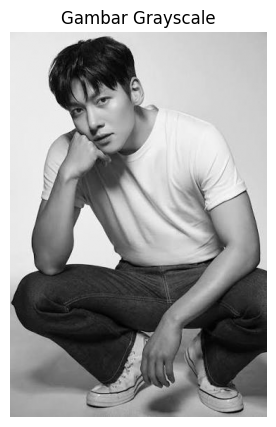

In [2]:
uploaded = files.upload()

nama_file = next(iter(uploaded.keys()))

# Membaca gambar dan mengubahnya menjadi grayscale
gambar = cv2.imread(nama_file)
gambar_gray = cv2.cvtColor(gambar, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(7, 5))
plt.imshow(gambar_gray, cmap='gray')
plt.title('Gambar Grayscale')
plt.axis('off')
plt.show()

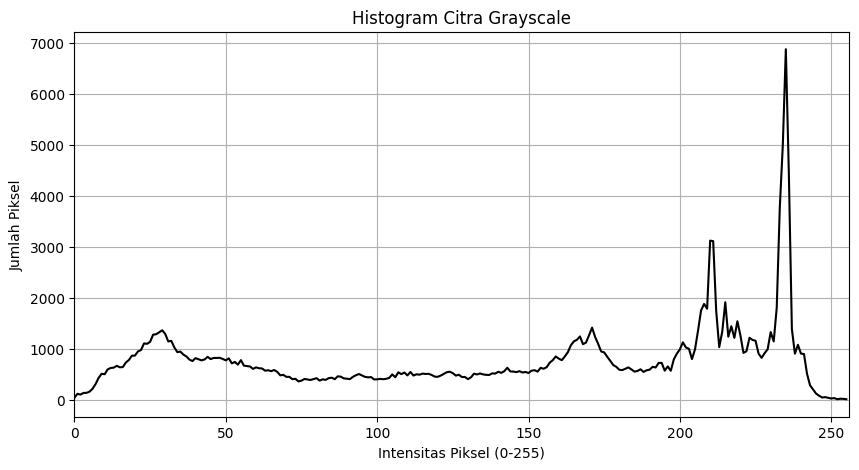

In [3]:
# Menghitung histogram intensitas piksel
histogram = cv2.calcHist(
    [gambar_gray],
    [0],
    None,
    [256],
    [0, 256]
)

plt.figure(figsize=(10, 5))
plt.plot(histogram, color='black')
plt.title("Histogram Citra Grayscale")
plt.xlabel("Intensitas Piksel (0-255)")
plt.ylabel("Jumlah Piksel")
plt.xlim([0, 256])
plt.grid(True)
plt.show()


In [4]:
rata_rata = np.mean(gambar_gray)
minimum = np.min(gambar_gray)
maksimum = np.max(gambar_gray)

simpangan_baku = np.std(gambar_gray)

print("Hasil Analisis Citra")
print("____________________")
print(f"Intensitas rata-rata: {rata_rata:.2f}")
print(f"Intensitas Minimum: {minimum}")
print(f"Intensitas Maksimum: {maksimum}")
print(f"Simpangan Baku: {simpangan_baku:.2f}")

if rata_rata < 85:
  print("Kategori Citra cenderung gelap")
elif rata_rata < 170:
  print("Kategori Citra memiliki kecerahan menengah")
else:
  print("Kategori citra cenderung terang")

Hasil Analisis Citra
____________________
Intensitas rata-rata: 144.58
Intensitas Minimum: 0
Intensitas Maksimum: 255
Simpangan Baku: 76.45
Kategori Citra memiliki kecerahan menengah


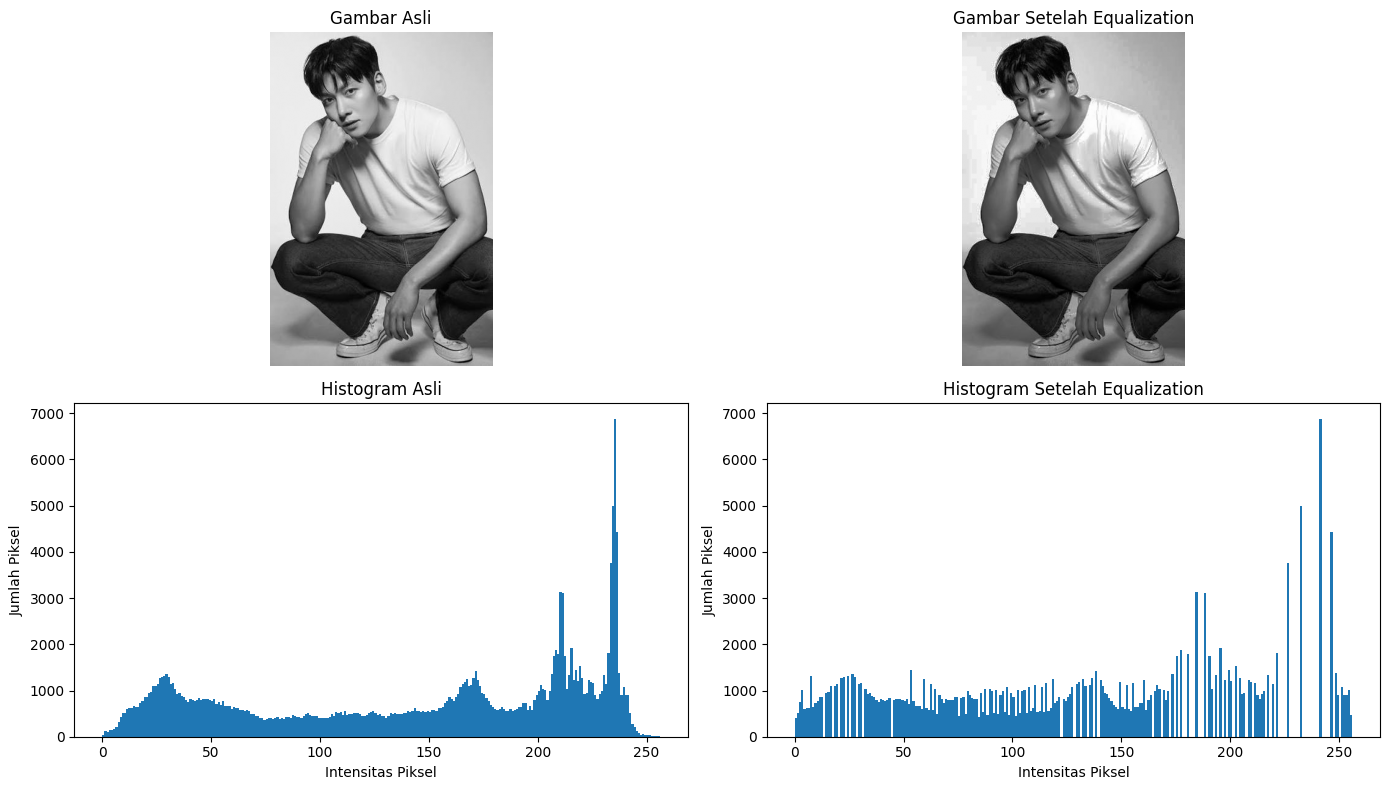

In [6]:
# Meningkatkan kontras menggunakan Histogram Equalization
gambar_equalized = cv2.equalizeHist(gambar_gray)

# Membuat perbandingan gambar
plt.figure(figsize=(14, 8))

plt.subplot(2, 2, 1)
plt.imshow(gambar_gray, cmap= 'gray')
plt.title('Gambar Asli')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(gambar_equalized, cmap= 'gray')
plt.title('Gambar Setelah Equalization')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.hist(gambar_gray.ravel(), bins=256, range=(0, 256))
plt.title("Histogram Asli")
plt.xlabel("Intensitas Piksel")
plt.ylabel("Jumlah Piksel")

plt.subplot(2, 2, 4)
plt.hist(gambar_equalized.ravel(), bins=256, range=(0, 256))
plt.title("Histogram Setelah Equalization")
plt.xlabel("Intensitas Piksel")
plt.ylabel("Jumlah Piksel")

plt.tight_layout()
plt.show()
